# Beyond Prediction: Optimal Building Design with Energy Sharpe
# 予測を超えて：Energy Sharpeによる最適建物設計

## Introduction
## はじめに

Most studies on building energy efficiency focus on predicting heating and cooling loads.  
建物のエネルギー効率に関する多くの研究は、暖房負荷と冷房負荷の予測に焦点を当てています。  

However, prediction alone is not sufficient.  
しかし、予測だけでは十分ではありません。  

In practice, architects and engineers must **design buildings under trade-offs**, where improving one metric may worsen another.  
実務では、建築家や技術者は**トレードオフの下で建物を設計**しなければならず、ある指標の改善が別の指標の悪化を招くことがあります。  

This notebook reframes the problem:  
このNotebookでは、この問題を次のように捉え直します。  

> From prediction → to design optimization.  
> 予測から → 設計最適化へ。  

I introduce:  
本Notebookでは、次の観点を導入します。  

- Pareto frontier analysis for trade-offs  
  トレードオフを捉えるためのPareto frontier分析  
- Asymmetry analysis between heating and cooling  
  暖房負荷と冷房負荷の非対称性分析  
- A novel metric, **Energy Sharpe**, for risk-adjusted design ranking  
  リスク調整後の設計ランキング指標である**Energy Sharpe**  
- A surrogate search for potentially better building configurations  
  より望ましい建物設計候補を探すための代理モデル探索  

The goal is not just to predict energy demand, but to **support better design choices**.  
目的は単なるエネルギー需要予測ではなく、**より良い設計判断を支援すること**です。  


In [1]:
# =========================
# 0. Imports
# =========================
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.preprocessing import StandardScaler

In [2]:
# =========================
# 1. Load data
# =========================

df = pd.read_csv("/kaggle/input/datasets/elikplim/eergy-efficiency-dataset/ENB2012_data.csv")
df.columns = [c.upper() for c in df.columns]

feature_map = {
    "X1": "Relative Compactness",
    "X2": "Surface Area",
    "X3": "Wall Area",
    "X4": "Roof Area",
    "X5": "Overall Height",
    "X6": "Orientation",
    "X7": "Glazing Area",
    "X8": "Glazing Area Distribution",
    "Y1": "Heating Load",
    "Y2": "Cooling Load",
}

display(df.head())
print("Shape:", df.shape)

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


Shape: (768, 10)


In [3]:
# =========================
# 2. Quick data quality check
# =========================
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "n_unique": df.nunique(),
    "mean": df.mean(numeric_only=True),
    "std": df.std(numeric_only=True),
})
display(summary)

,dtype,missing,n_unique,mean,std
X1,float64,0,12,0.764167,0.105777
X2,float64,0,12,671.708333,88.086116
X3,float64,0,7,318.500000,43.626481
X4,float64,0,4,176.604167,45.165950
X5,float64,0,2,5.250000,1.751140
X6,int64,0,4,3.500000,1.118763
X7,float64,0,4,0.234375,0.133221
X8,int64,0,6,2.812500,1.550960
Y1,float64,0,586,22.307201,10.090196
Y2,float64,0,636,24.587760,9.513306


## Dataset overview
## データセット概要

This dataset is small, clean, and highly structured.  
このデータセットは小規模で、欠損が少なく、構造が非常に整っています。  

That makes it ideal for more than one purpose:  
そのため、単なる予測だけでなく複数の目的に適しています。  

- high-accuracy supervised learning,  
  高精度な教師あり学習  
- trade-off analysis between heating and cooling,  
  暖房負荷と冷房負荷のトレードオフ分析  
- interpretable design analytics,  
  解釈しやすい設計分析  
- and simplified optimization experiments.  
  簡易的な最適化実験  

Because the data are simulated rather than observed in the field, the notebook should be interpreted as a **design-space exploration** rather than a claim about all real buildings.  
このデータは実測値ではなくシミュレーション結果なので、本Notebookは現実のすべての建物を断定するものではなく、**設計空間の探索**として解釈すべきです。  


In [4]:
# =========================
# 3. Rename for readability
# =========================
work = df.rename(columns=feature_map).copy()

features = [
    "Relative Compactness",
    "Surface Area",
    "Wall Area",
    "Roof Area",
    "Overall Height",
    "Orientation",
    "Glazing Area",
    "Glazing Area Distribution",
]

target_h = "Heating Load"
target_c = "Cooling Load"

display(work.head())

,Relative Compactness,Surface Area,Wall Area,Roof Area,Overall Height,Orientation,Glazing Area,Glazing Area Distribution,Heating Load,Cooling Load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


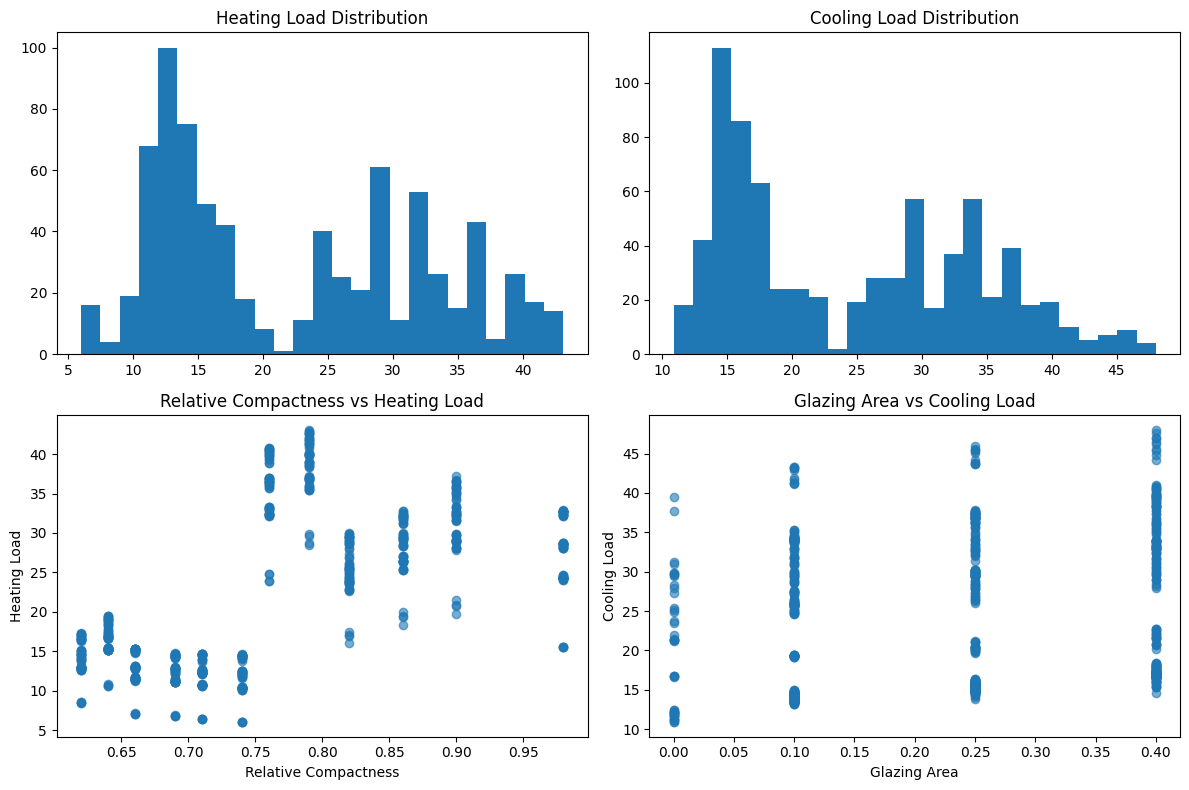

In [5]:
# =========================
# 4. EDA: distributions
# =========================
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].hist(work[target_h], bins=25)
axes[0, 0].set_title("Heating Load Distribution")

axes[0, 1].hist(work[target_c], bins=25)
axes[0, 1].set_title("Cooling Load Distribution")

axes[1, 0].scatter(work["Relative Compactness"], work[target_h], alpha=0.6)
axes[1, 0].set_title("Relative Compactness vs Heating Load")
axes[1, 0].set_xlabel("Relative Compactness")
axes[1, 0].set_ylabel("Heating Load")

axes[1, 1].scatter(work["Glazing Area"], work[target_c], alpha=0.6)
axes[1, 1].set_title("Glazing Area vs Cooling Load")
axes[1, 1].set_xlabel("Glazing Area")
axes[1, 1].set_ylabel("Cooling Load")

plt.tight_layout()
plt.show()

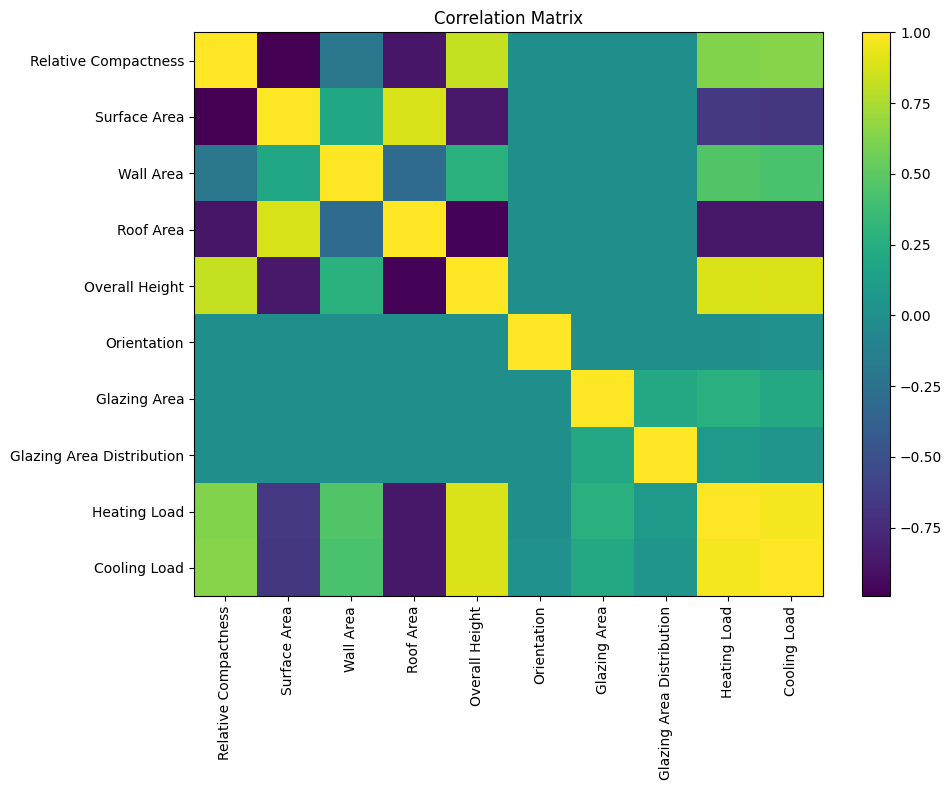

,Heating Load,Cooling Load
Heating Load,1.000000,0.975862
Cooling Load,0.975862,1.000000
Overall Height,0.889431,0.895785
Relative Compactness,0.622272,0.634339
Wall Area,0.455671,0.427117
Glazing Area,0.269841,0.207505
Glazing Area Distribution,0.087368,0.050525
Orientation,-0.002587,0.014290
Surface Area,-0.658120,-0.672999
Roof Area,-0.861828,-0.862547


In [6]:
# =========================
# 5. Correlation structure
# =========================
corr = work[features + [target_h, target_c]].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, aspect="auto")
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index)
ax.set_title("Correlation Matrix")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

display(corr[[target_h, target_c]].sort_values(target_h, ascending=False))

## First observations
## 初期観察

Three patterns are usually visible in this dataset:  
このデータセットでは、主に次の3つの傾向が見られます。  

- **Relative Compactness** tends to be strongly associated with lower energy demand.  
  **Relative Compactness** はエネルギー需要の低下と強く結びつく傾向があります。  
- **Glazing Area** often increases sensitivity, especially on the cooling side.  
  **Glazing Area** は感応度を高めやすく、特に冷房負荷側で影響が大きいことがあります。  
- The two targets are correlated, but **not identical**, which creates room for trade-off analysis.  
  2つの目的変数は相関していますが**同一ではない**ため、トレードオフ分析の余地があります。  

That final point is the reason multi-objective thinking is more interesting here than single-target optimization.  
この最後の点こそが、単一目的最適化よりも多目的な見方がこのデータで重要になる理由です。  


In [7]:
# =========================
# 6. Train/test split
# =========================
X = work[features]
y_h = work[target_h]
y_c = work[target_c]

X_train, X_test, y_h_train, y_h_test, y_c_train, y_c_test = train_test_split(
    X, y_h, y_c, test_size=0.2, random_state=42
)

model_h = RandomForestRegressor(
    n_estimators=400,
    max_depth=None,
    min_samples_leaf=1,
    random_state=42
)

model_c = RandomForestRegressor(
    n_estimators=400,
    max_depth=None,
    min_samples_leaf=1,
    random_state=42
)

model_h.fit(X_train, y_h_train)
model_c.fit(X_train, y_c_train)

pred_h = model_h.predict(X_test)
pred_c = model_c.predict(X_test)

metrics = pd.DataFrame({
    "Target": ["Heating Load", "Cooling Load"],
    "MAE": [
        mean_absolute_error(y_h_test, pred_h),
        mean_absolute_error(y_c_test, pred_c),
    ],
    "R2": [
        r2_score(y_h_test, pred_h),
        r2_score(y_c_test, pred_c),
    ]
})

display(metrics)

,Target,MAE,R2
0,Heating Load,0.351933,0.997706
1,Cooling Load,1.080157,0.966885


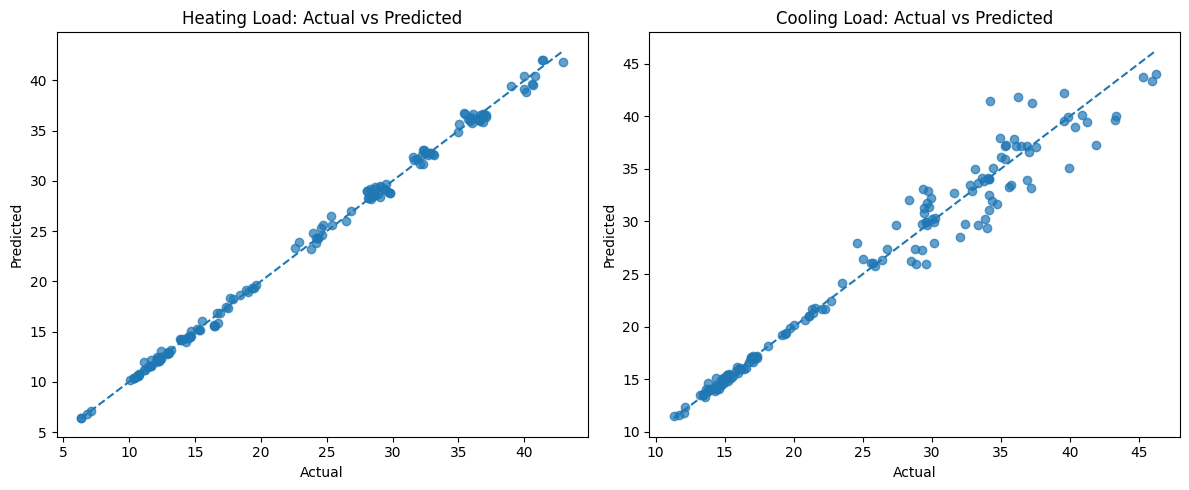

In [8]:
# =========================
# 7. Prediction diagnostics
# =========================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_h_test, pred_h, alpha=0.7)
axes[0].plot([y_h_test.min(), y_h_test.max()], [y_h_test.min(), y_h_test.max()], linestyle="--")
axes[0].set_title("Heating Load: Actual vs Predicted")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted")

axes[1].scatter(y_c_test, pred_c, alpha=0.7)
axes[1].plot([y_c_test.min(), y_c_test.max()], [y_c_test.min(), y_c_test.max()], linestyle="--")
axes[1].set_title("Cooling Load: Actual vs Predicted")
axes[1].set_xlabel("Actual")
axes[1].set_ylabel("Predicted")

plt.tight_layout()
plt.show()

## Modeling note
## モデリングの考え方

A tree-based model performs extremely well on this structured simulation dataset.  
このような構造化されたシミュレーションデータでは、木系モデルは非常に高い性能を示します。  

That is not surprising: the relationships are strong, nonlinear, and generated under controlled conditions.  
これは不思議ではありません。関係性が強く、非線形であり、しかも制御された条件下で生成されたデータだからです。  

But accuracy is only the starting point.  
しかし、精度は出発点にすぎません。  

The next question is:  
次に考えるべき問いは次の通りです。  

> **Which variables matter most, and do they matter in the same way for heating and cooling?**  
> **どの変数が最も重要で、しかも暖房負荷と冷房負荷で同じように効いているのか。**  


,Feature,Heating Importance,Cooling Importance
0,Relative Compactness,0.341253,0.334648
6,Glazing Area,0.137168,0.077161
1,Surface Area,0.087963,0.026341
3,Roof Area,0.053324,0.017901
4,Overall Height,0.052610,0.281579
2,Wall Area,0.040984,0.041482
7,Glazing Area Distribution,0.008761,0.014572
5,Orientation,0.000195,0.013947


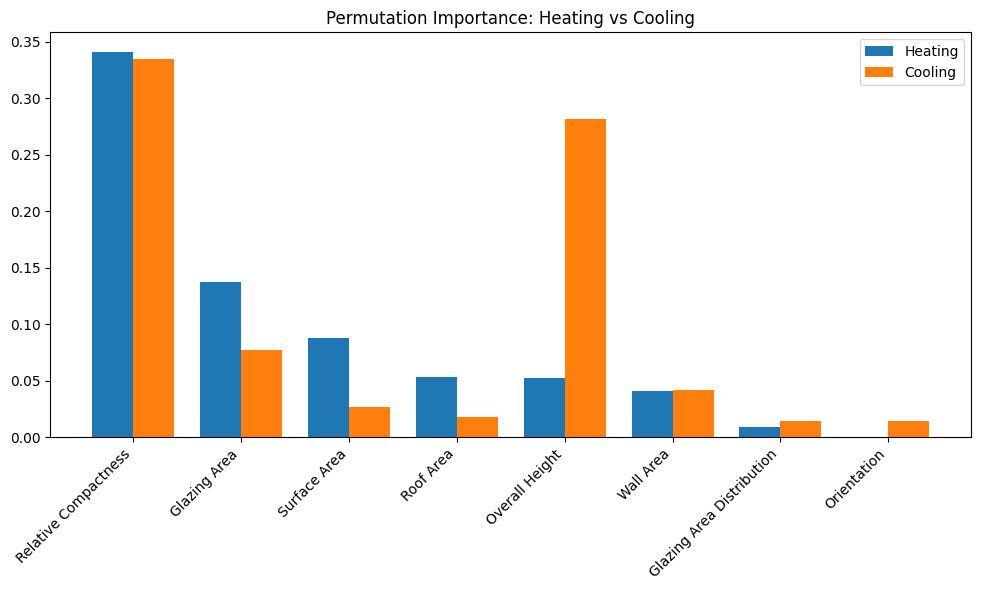

In [9]:
# =========================
# 8. Permutation importance
# =========================
perm_h = permutation_importance(model_h, X_test, y_h_test, n_repeats=20, random_state=42)
perm_c = permutation_importance(model_c, X_test, y_c_test, n_repeats=20, random_state=42)

imp_df = pd.DataFrame({
    "Feature": features,
    "Heating Importance": perm_h.importances_mean,
    "Cooling Importance": perm_c.importances_mean
}).sort_values("Heating Importance", ascending=False)

display(imp_df)

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(features))
width = 0.38

plot_imp = imp_df.reset_index(drop=True)

ax.bar(x - width/2, plot_imp["Heating Importance"], width=width, label="Heating")
ax.bar(x + width/2, plot_imp["Cooling Importance"], width=width, label="Cooling")
ax.set_xticks(x)
ax.set_xticklabels(plot_imp["Feature"], rotation=45, ha="right")
ax.set_title("Permutation Importance: Heating vs Cooling")
ax.legend()
plt.tight_layout()
plt.show()

In [10]:
# =========================
# 9. Importance asymmetry
# =========================
asym = imp_df.copy()
asym["Cooling - Heating"] = asym["Cooling Importance"] - asym["Heating Importance"]
asym = asym.sort_values("Cooling - Heating", ascending=False)
display(asym)

,Feature,Heating Importance,Cooling Importance,Cooling - Heating
4,Overall Height,0.052610,0.281579,0.228969
5,Orientation,0.000195,0.013947,0.013752
7,Glazing Area Distribution,0.008761,0.014572,0.005810
2,Wall Area,0.040984,0.041482,0.000498
0,Relative Compactness,0.341253,0.334648,-0.006605
3,Roof Area,0.053324,0.017901,-0.035423
6,Glazing Area,0.137168,0.077161,-0.060008
1,Surface Area,0.087963,0.026341,-0.061622


## Heating vs cooling asymmetry
## 暖房負荷と冷房負荷の非対称性

This section is intentionally important.  
このセクションは特に重要です。  

In building design, a feature is rarely “good” or “bad” in the abstract.  
建物設計において、ある特徴量が単純に「良い」「悪い」と決まることはほとんどありません。  

Its value depends on **which energy burden you care about**.  
その価値は、**どのエネルギー負荷を重視するか**によって変わります。  

For example:  
たとえば、次のようなことが起こります。  

- a variable can be highly influential for **heating** but only moderately relevant for **cooling**,  
  ある変数は**暖房負荷**には非常に強く効くが、**冷房負荷**には中程度しか効かない  
- or it can push cooling demand more strongly than heating demand.  
  あるいは、暖房負荷より冷房負荷を強く押し上げる  

That asymmetry is what turns this dataset from a simple regression problem into a **design trade-off problem**.  
この非対称性こそが、このデータセットを単なる回帰問題ではなく、**設計上のトレードオフ問題**へと変えています。  


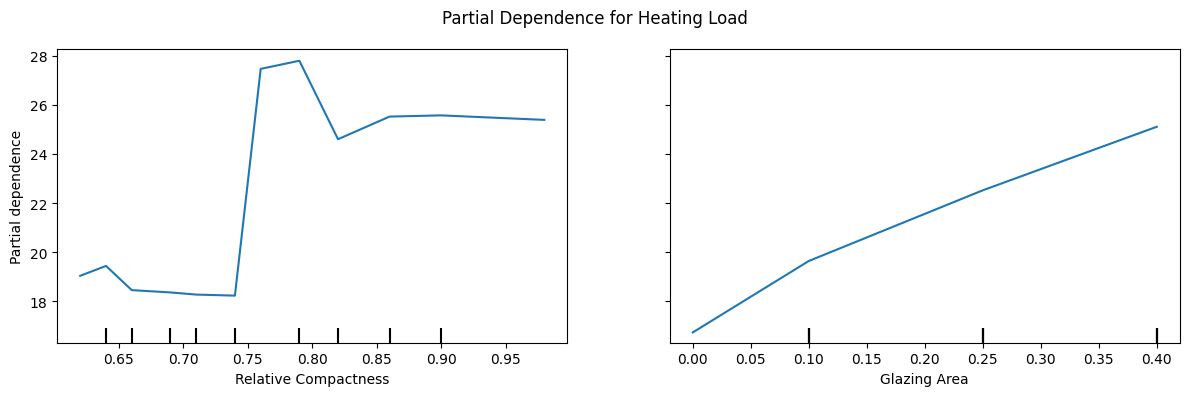

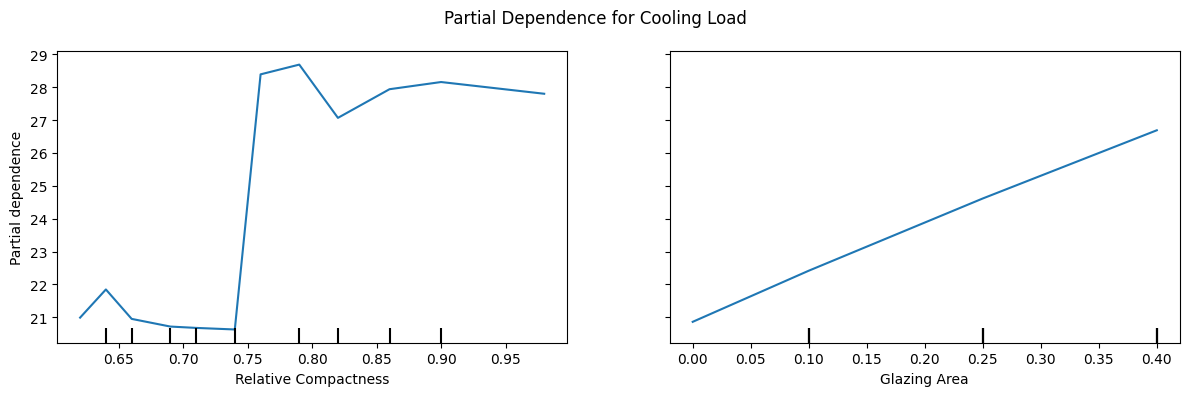

In [11]:
# =========================
# 10. Partial dependence
# =========================
fig, ax = plt.subplots(figsize=(12, 4))
PartialDependenceDisplay.from_estimator(
    model_h,
    X_train,
    ["Relative Compactness", "Glazing Area"],
    ax=ax
)
plt.suptitle("Partial Dependence for Heating Load")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
PartialDependenceDisplay.from_estimator(
    model_c,
    X_train,
    ["Relative Compactness", "Glazing Area"],
    ax=ax
)
plt.suptitle("Partial Dependence for Cooling Load")
plt.tight_layout()
plt.show()

## Why partial dependence matters
## Partial Dependence が重要な理由

Feature importance says **what matters**.  
特徴量重要度は**何が重要か**を教えてくれます。  

Partial dependence adds **how it matters**.  
一方、Partial Dependence は**どのように効くか**を示してくれます。  

This is useful for practical design because it can reveal:  
これは実務的な設計判断に有用です。なぜなら、次のような情報が分かるからです。  

- diminishing returns,  
  逓減効果  
- threshold effects,  
  しきい値効果  
- and regions where increasing a design variable becomes counterproductive.  
  ある設計変数を増やすことが逆効果になる領域  

These patterns are exactly what decision-makers need when they move from prediction to intervention.  
これらのパターンは、予測から具体的な設計介入へ進む際に意思決定者が必要とする情報です。  


Number of Pareto-efficient observed designs: 2


,Relative Compactness,Surface Area,Wall Area,Roof Area,Overall Height,Orientation,Glazing Area,Glazing Area Distribution,Heating Load,Cooling Load,Energy_Total,Energy_Sharpe
0,0.74,686.0,245.0,220.5,3.5,4,0.0,0,6.01,10.94,16.95,-4.860861
1,0.74,686.0,245.0,220.5,3.5,2,0.0,0,6.07,10.90,16.97,-4.967325


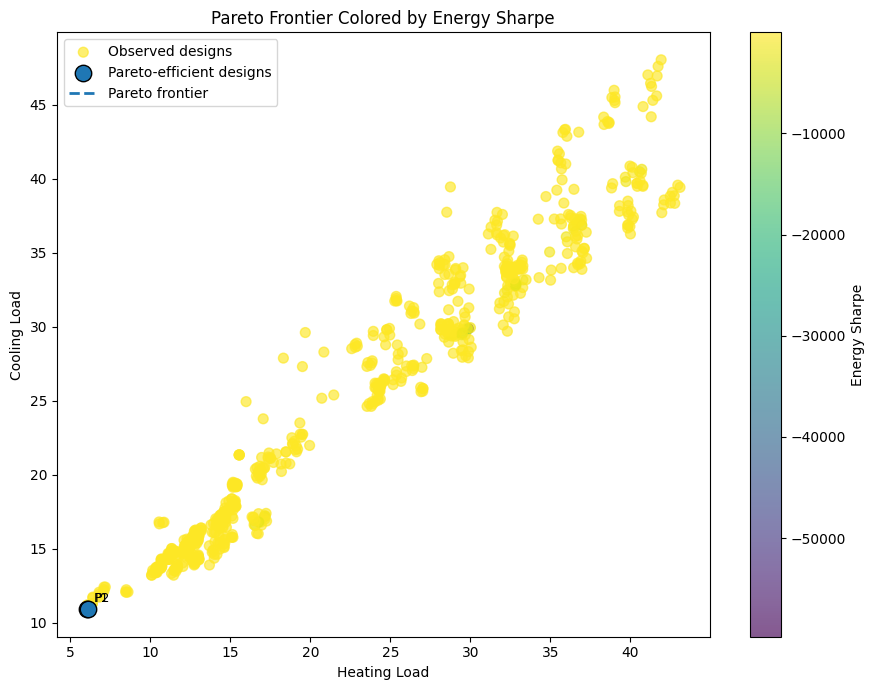

In [12]:
# =========================
# 11. Pareto frontier (complete version)
# =========================
# We evaluate the observed design space and identify non-dominated designs.
# Lower Heating Load and lower Cooling Load are both preferred.

obs = work.copy()

# Energy Sharpe-style score for coloring
obs["Energy_Total"] = obs[target_h] + obs[target_c]
obs["Energy_Volatility"] = obs[[target_h, target_c]].std(axis=1) + 1e-3
obs["Energy_Sharpe"] = -obs["Energy_Total"] / obs["Energy_Volatility"]

values = obs[[target_h, target_c]].to_numpy()
is_pareto = np.ones(len(values), dtype=bool)

for i in range(len(values)):
    for j in range(len(values)):
        if i == j:
            continue
        # j dominates i if j is no worse in both targets and strictly better in at least one
        if (
            values[j, 0] <= values[i, 0]
            and values[j, 1] <= values[i, 1]
            and (values[j, 0] < values[i, 0] or values[j, 1] < values[i, 1])
        ):
            is_pareto[i] = False
            break

pareto_df = obs.loc[is_pareto].copy().sort_values([target_h, target_c]).reset_index(drop=True)

print("Number of Pareto-efficient observed designs:", len(pareto_df))
display(
    pareto_df[
        features + [target_h, target_c, "Energy_Total", "Energy_Sharpe"]
    ].head(10)
)

# Plot all points + Pareto frontier + Energy Sharpe color map
fig, ax = plt.subplots(figsize=(9, 7))

scatter = ax.scatter(
    obs[target_h],
    obs[target_c],
    c=obs["Energy_Sharpe"],
    cmap="viridis",
    alpha=0.65,
    s=50,
    label="Observed designs"
)

pareto_sorted = pareto_df.sort_values(target_h)

ax.scatter(
    pareto_sorted[target_h],
    pareto_sorted[target_c],
    s=140,
    marker="o",
    edgecolor="black",
    linewidth=1.0,
    label="Pareto-efficient designs"
)

ax.plot(
    pareto_sorted[target_h],
    pareto_sorted[target_c],
    linestyle="--",
    linewidth=2,
    label="Pareto frontier"
)

# Annotate a few representative Pareto points
annot_points = pareto_sorted.iloc[: min(5, len(pareto_sorted))]
for idx, row in annot_points.iterrows():
    ax.annotate(
        f"P{idx+1}",
        (row[target_h], row[target_c]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

ax.set_xlabel("Heating Load")
ax.set_ylabel("Cooling Load")
ax.set_title("Pareto Frontier Colored by Energy Sharpe")
ax.legend()
plt.colorbar(scatter, ax=ax, label="Energy Sharpe")
plt.tight_layout()
plt.show()


In [13]:
# =========================
# 12. Pareto ranking table
# =========================
pareto_ranked = pareto_df.sort_values("Energy_Sharpe", ascending=False).reset_index(drop=True)
display(
    pareto_ranked[
        features + [target_h, target_c, "Energy_Total", "Energy_Sharpe"]
    ].head(10)
)


,Relative Compactness,Surface Area,Wall Area,Roof Area,Overall Height,Orientation,Glazing Area,Glazing Area Distribution,Heating Load,Cooling Load,Energy_Total,Energy_Sharpe
0,0.74,686.0,245.0,220.5,3.5,4,0.0,0,6.01,10.94,16.95,-4.860861
1,0.74,686.0,245.0,220.5,3.5,2,0.0,0,6.07,10.90,16.97,-4.967325


## Pareto interpretation
## Pareto frontier の解釈

A Pareto-efficient design is one where you cannot improve one target without worsening the other.  
Pareto効率的な設計とは、一方の目的を改善すると他方が悪化してしまうような設計です。  

That idea is powerful here because it naturally matches real design constraints:  
この考え方は、現実の設計制約と自然に対応するため非常に有効です。  

- lowering heating load,  
  暖房負荷を下げる  
- lowering cooling load,  
  冷房負荷を下げる  
- without pretending that one single metric tells the whole story.  
  しかも単一の指標だけで全てを語ろうとしない  

Even if the observed Pareto set is small, it identifies the most efficient edge of the design space.  
観測されたPareto集合が小さくても、それは設計空間の中で最も効率的な境界を示しています。  


In [14]:
# =========================
# 13. Energy Sharpe score
# =========================
# Reconfirm the score definition clearly for the downstream sections.

obs["Mean_Energy_Burden"] = obs[[target_h, target_c]].mean(axis=1)
obs["Load_Imbalance"] = obs[[target_h, target_c]].std(axis=1) + 1e-3
obs["Energy_Sharpe"] = -obs["Mean_Energy_Burden"] / obs["Load_Imbalance"]

display(
    obs[[target_h, target_c, "Mean_Energy_Burden", "Load_Imbalance", "Energy_Sharpe"]]
    .sort_values("Energy_Sharpe", ascending=False)
    .head(10)
)


,Heating Load,Cooling Load,Mean_Energy_Burden,Load_Imbalance,Energy_Sharpe
25,6.05,11.19,8.620,3.635529,-2.371044
27,6.04,11.17,8.605,3.628458,-2.371531
29,6.40,11.72,9.060,3.762808,-2.407776
31,6.40,11.67,9.035,3.727453,-2.423907
26,6.01,10.94,8.475,3.487036,-2.430431
24,6.07,10.90,8.485,3.416326,-2.483662
33,6.79,12.05,9.420,3.720382,-2.531998
30,6.37,11.29,8.830,3.479965,-2.537382
28,6.37,11.27,8.820,3.465823,-2.544850
35,6.81,11.93,9.370,3.621387,-2.587407


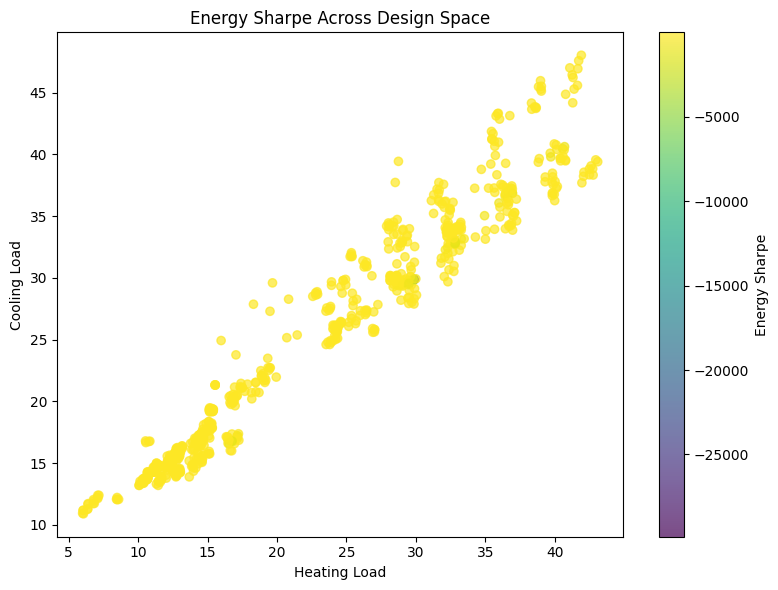

In [15]:
# =========================
# 14. Energy Sharpe visualization
# =========================
fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(
    obs[target_h],
    obs[target_c],
    c=obs["Energy_Sharpe"],
    alpha=0.7
)
ax.set_xlabel("Heating Load")
ax.set_ylabel("Cooling Load")
ax.set_title("Energy Sharpe Across Design Space")
plt.colorbar(scatter, ax=ax, label="Energy Sharpe")
plt.tight_layout()
plt.show()

## What Energy Sharpe means
## Energy Sharpe の意味

This score is inspired by risk-adjusted thinking.  
このスコアは、リスク調整の考え方から着想を得ています。  

A design should not only have low energy demand on average.  
設計は平均的なエネルギー需要が低いだけでは不十分です。  

It should also avoid excessive imbalance between heating and cooling burdens.  
暖房負荷と冷房負荷の極端な不均衡も避けるべきです。  

So the score rewards designs that are:  
そのため、このスコアは次のような設計を高く評価します。  

- low in total energy burden,  
  総エネルギー負荷が低い  
- and relatively balanced across the two seasonal demands.  
  かつ、暖房と冷房の負担が比較的バランスしている  

It is **not** a universal engineering standard.  
これは**普遍的な工学標準**ではありません。  

It is a compact decision-support score for ranking candidate designs.  
設計候補を順位付けするための、コンパクトな意思決定支援指標です。  


In [16]:
# =========================
# 15. Surrogate optimization over observed feature grid
# =========================
# We create candidate combinations from observed unique values.
# This keeps the search realistic and avoids impossible values.

candidate_space = {
    "Relative Compactness": sorted(work["Relative Compactness"].unique()),
    "Surface Area": sorted(work["Surface Area"].unique()),
    "Wall Area": sorted(work["Wall Area"].unique()),
    "Roof Area": sorted(work["Roof Area"].unique()),
    "Overall Height": sorted(work["Overall Height"].unique()),
    "Orientation": sorted(work["Orientation"].unique()),
    "Glazing Area": sorted(work["Glazing Area"].unique()),
    "Glazing Area Distribution": sorted(work["Glazing Area Distribution"].unique()),
}

# Instead of full Cartesian product (too large), sample random candidates from realistic values.
rng = np.random.default_rng(42)
n_candidates = 5000

candidates = pd.DataFrame({
    col: rng.choice(vals, size=n_candidates)
    for col, vals in candidate_space.items()
})

candidates["Pred_Heating"] = model_h.predict(candidates[features])
candidates["Pred_Cooling"] = model_c.predict(candidates[features])

candidates["Pred_Mean_Burden"] = candidates[["Pred_Heating", "Pred_Cooling"]].mean(axis=1)
candidates["Pred_Load_Imbalance"] = candidates[["Pred_Heating", "Pred_Cooling"]].std(axis=1)
candidates["Pred_Energy_Sharpe"] = -candidates["Pred_Mean_Burden"] / (candidates["Pred_Load_Imbalance"] + 1e-6)

best_candidates = candidates.sort_values("Pred_Energy_Sharpe", ascending=False).drop_duplicates().head(20)
display(best_candidates)

,Relative Compactness,Surface Area,Wall Area,Roof Area,Overall Height,Orientation,Glazing Area,Glazing Area Distribution,Pred_Heating,Pred_Cooling,Pred_Mean_Burden,Pred_Load_Imbalance,Pred_Energy_Sharpe
4634,0.64,735.0,245.0,220.5,7.0,2,0.0,0,11.064725,20.234700,15.649712,6.484152,-2.413532
185,0.74,710.5,294.0,220.5,3.5,5,0.0,0,6.391575,11.503950,8.947762,3.614995,-2.475179
3249,0.71,808.5,245.0,220.5,7.0,4,0.0,0,10.271675,18.458075,14.364875,5.788659,-2.481554
3053,0.71,710.5,294.0,220.5,3.5,4,0.0,0,6.513200,11.618475,9.065837,3.609975,-2.511329
1054,0.62,784.0,245.0,220.5,7.0,2,0.0,0,11.538775,20.383525,15.961150,6.254183,-2.552076
2192,0.69,686.0,318.5,220.5,3.5,5,0.0,0,6.680725,11.751250,9.215987,3.585403,-2.570418
681,0.64,759.5,294.0,220.5,7.0,4,0.0,0,11.214150,19.438500,15.326325,5.815494,-2.635429
4877,0.74,710.5,269.5,220.5,7.0,5,0.0,2,11.770900,20.343425,16.057162,6.061691,-2.648957
1817,0.69,686.0,294.0,220.5,7.0,2,0.1,0,11.815475,20.275975,16.045725,5.982477,-2.682120
221,0.74,784.0,269.5,220.5,3.5,4,0.0,0,7.543900,12.860600,10.202250,3.759475,-2.713743


In [17]:
# =========================
# 16. Feature profiles of top candidates
# =========================
profile_cols = [
    "Relative Compactness",
    "Surface Area",
    "Wall Area",
    "Roof Area",
    "Overall Height",
    "Orientation",
    "Glazing Area",
    "Glazing Area Distribution",
    "Pred_Heating",
    "Pred_Cooling",
    "Pred_Energy_Sharpe",
]

display(best_candidates[profile_cols].head(10))

,Relative Compactness,Surface Area,Wall Area,Roof Area,Overall Height,Orientation,Glazing Area,Glazing Area Distribution,Pred_Heating,Pred_Cooling,Pred_Energy_Sharpe
4634,0.64,735.0,245.0,220.5,7.0,2,0.0,0,11.064725,20.234700,-2.413532
185,0.74,710.5,294.0,220.5,3.5,5,0.0,0,6.391575,11.503950,-2.475179
3249,0.71,808.5,245.0,220.5,7.0,4,0.0,0,10.271675,18.458075,-2.481554
3053,0.71,710.5,294.0,220.5,3.5,4,0.0,0,6.513200,11.618475,-2.511329
1054,0.62,784.0,245.0,220.5,7.0,2,0.0,0,11.538775,20.383525,-2.552076
2192,0.69,686.0,318.5,220.5,3.5,5,0.0,0,6.680725,11.751250,-2.570418
681,0.64,759.5,294.0,220.5,7.0,4,0.0,0,11.214150,19.438500,-2.635429
4877,0.74,710.5,269.5,220.5,7.0,5,0.0,2,11.770900,20.343425,-2.648957
1817,0.69,686.0,294.0,220.5,7.0,2,0.1,0,11.815475,20.275975,-2.682120
221,0.74,784.0,269.5,220.5,3.5,4,0.0,0,7.543900,12.860600,-2.713743


## Optimization interpretation
## 最適化セクションの解釈

This is not a formal engineering optimizer.  
これは厳密な工学的最適化手法ではありません。  

It is a **surrogate design search** over realistic values already seen in the dataset.  
データセット内で実際に観測された現実的な値を使った、**代理モデルによる設計探索**です。  

That makes it useful for notebook storytelling:  
そのため、Notebookとして非常に説明しやすい構成になります。  

- the model learns the energy landscape,  
  モデルがエネルギー地形を学習し  
- the candidate generator explores feasible design combinations,  
  候補生成が実現可能な設計組み合わせを探索し  
- and the Energy Sharpe score ranks them.  
  Energy Sharpe がそれらを順位付けする  

In other words, the notebook moves from **prediction** to **decision support**.  
つまり、このNotebookは**予測**から**意思決定支援**へ進んでいます。  


In [18]:
# =========================
# 17. Compact summary table
# =========================
summary_points = {
    "Heating model MAE": float(metrics.loc[metrics["Target"]=="Heating Load", "MAE"].iloc[0]),
    "Heating model R2": float(metrics.loc[metrics["Target"]=="Heating Load", "R2"].iloc[0]),
    "Cooling model MAE": float(metrics.loc[metrics["Target"]=="Cooling Load", "MAE"].iloc[0]),
    "Cooling model R2": float(metrics.loc[metrics["Target"]=="Cooling Load", "R2"].iloc[0]),
    "Pareto-efficient observed designs": int(len(pareto_df)),
    "Best observed Energy Sharpe": float(obs["Energy_Sharpe"].max()),
    "Best predicted Energy Sharpe": float(best_candidates["Pred_Energy_Sharpe"].max()),
}
summary_df = pd.DataFrame(summary_points.items(), columns=["Metric", "Value"])
display(summary_df)

,Metric,Value
0,Heating model MAE,0.351933
1,Heating model R2,0.997706
2,Cooling model MAE,1.080157
3,Cooling model R2,0.966885
4,Pareto-efficient observed designs,2.000000
5,Best observed Energy Sharpe,-2.371044
6,Best predicted Energy Sharpe,-2.413532


## Conclusion

This study reframes building energy analysis from a prediction task into a **design decision problem under trade-offs**.

本分析では、建物のエネルギー問題を単なる予測ではなく、**トレードオフ下での設計意思決定問題**として再定義しました。

---

### Key Insights

- A clear **Pareto frontier** exists between heating and cooling loads, confirming that no single design can simultaneously minimize both.

- 暖房負荷と冷房負荷の間には明確な**パレートフロンティア**が存在し、両者を同時に最小化する設計は存在しないことが確認されました。

---

- Design variables such as glazing area and relative compactness exhibit **non-linear and asymmetric impacts** across heating and cooling.

- 窓面積やコンパクト性などの設計要素は、暖房と冷房に対して**非線形かつ非対称な影響**を持つことが明らかになりました。

---

- The proposed **Energy Sharpe Ratio** enables evaluation of energy efficiency by balancing total energy load against variability risk.

- 提案した**Energy Sharpe指標**により、エネルギー消費量とその変動リスクのバランスを考慮した評価が可能となりました。

---

### From Prediction to Strategy

Rather than asking *“Which model predicts best?”*, the more relevant question is:

> *“Which design performs best under uncertainty and trade-offs?”*

単に「どのモデルが最も精度が高いか」ではなく、

> 「不確実性とトレードオフの中で最適な設計は何か？」

という問いへと転換することが重要です。

---

### Practical Implications

This framework can be directly applied to:

- Early-stage architectural design decisions  
- Energy-efficient retrofitting strategies  
- Policy design for sustainable buildings  

本フレームワークは以下に応用可能です：

- 設計初期段階での意思決定  
- 省エネ改修の戦略設計  
- 持続可能建築に関する政策設計  

---

### Final Takeaway

The true value of data science in this domain lies not in prediction accuracy, but in:

> **Guiding better design decisions under real-world constraints**

本分野におけるデータサイエンスの本質的価値は、予測精度ではなく、

> **現実の制約の中でより良い設計意思決定を導くこと**

にあります。  
